In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import numpy as np
import xarray as xr

from fast_o3_iv import utils, plots
from fast_o3_iv.modeling.train import DatasetConfig
import fast_o3_iv.bias_correction as bc
import fast_o3_iv.attributable_fraction as af

In [3]:
def make_config(source_id, experiment, start, stop):
    return DatasetConfig(
        source_id=source_id,
        cmip_experiment_id=experiment,
        variable_setname="setC",
        year_range=range(start, stop),
    )

config_hist_original   = make_config("CESM2-WACCM6", "historical", 1975, 2015)
config_hist_synthetic  = make_config("CESM2",        "historical", 1975, 2015)

config_ssp245_original  = make_config("CESM2-WACCM6", "ssp245", 2015, 2055)
config_ssp245_synthetic = make_config("CESM2",        "ssp245", 2015, 2055)

config_ssp585_original  = make_config("CESM2-WACCM6", "ssp585", 2015, 2055)
config_ssp585_synthetic = make_config("CESM2",        "ssp585", 2015, 2055)

In [5]:
def load_osdma8_window(
    config,
    year_slice,
    *,
    mode="inference",
    model_key="GPR-local",
):
    file_path = bc.return_osdma8_bc_path(mode, config, model_key)
    ds = xr.open_dataset(file_path)
    return ds.sel(time=year_slice)


def concat_members(
    configs,
    year_slice,
    *,
    dim="ensemble_member",
    mode="inference",
    model_key="GPR-local",
):
    if isinstance(mode, str):
        modes = [mode] * len(configs)
    else:
        modes = mode

    datasets = [
        load_osdma8_window(cfg, year_slice, mode=md, model_key=model_key)
        for cfg, md in zip(configs, modes)
    ]
    return xr.concat(datasets, dim=dim)

hist_years = slice("2005", "2014")
fut_years = slice("2045", "2054")

hist_osdma8_sel = concat_members(
    [config_hist_original, config_hist_synthetic],
    hist_years,
)

ssp245_osdma8_sel = concat_members(
    [config_ssp245_original, config_ssp245_synthetic],
    fut_years,
)

ssp585_osdma8_sel = concat_members(
    [config_ssp585_original, config_ssp585_synthetic],
    fut_years,
    mode=["targets", "inference"],
)

/tmp/ipykernel_2129116/1576346018.py:30: FutureWarning: In a future version of xarray the default value for data_vars will change from data_vars='all' to data_vars=None. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set data_vars explicitly.
  return xr.concat(datasets, dim=dim)
/tmp/ipykernel_2129116/1576346018.py:30: FutureWarning: In a future version of xarray the default value for data_vars will change from data_vars='all' to data_vars=None. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set data_vars explicitly.
  return xr.concat(datasets, dim=dim)
/tmp/ipykernel_2129116/1576346018.py:30: FutureWarning: In a futur

In [6]:
def load_af_window(
    config,
    year_slice,
    *,
    mode="inference",
    model_key="GPR-local",
):
    file_path = af.return_af_path(mode, config, model_key) 
    ds = xr.open_dataset(file_path)
    return ds.sel(time=year_slice)


def concat_members(
    configs,
    year_slice,
    *,
    dim="ensemble_member",
    mode="inference",
    model_key="GPR-local",
):
    if isinstance(mode, str):
        modes = [mode] * len(configs)
    else:
        modes = mode

    datasets = [
        load_af_window(cfg, year_slice, mode=md, model_key=model_key)
        for cfg, md in zip(configs, modes)
    ]
    return xr.concat(datasets, dim=dim)

hist_years = slice("2005", "2014")
fut_years = slice("2045", "2054")

hist_af_sel = concat_members(
    [config_hist_original, config_hist_synthetic],
    hist_years,
)

ssp245_af_sel = concat_members(
    [config_ssp245_original, config_ssp245_synthetic],
    fut_years,
)

ssp585_af_sel = concat_members(
    [config_ssp585_original, config_ssp585_synthetic],
    fut_years,
    mode=["targets", "inference"],
)

In [6]:
ds_hist_osdma_mean = ds_hist.mean(dim=['ensemble_member', 'time'])
ds_ssp_osdma_mean = ds_ssp.mean(dim=['ensemble_member', 'time'])

In [7]:
hist_af_healthrange = af.calc_af_range(ds_hist_osdma_mean,'osdma_bc')
ssp_af_healthrange = af.calc_af_range(ds_ssp_osdma_mean,'osdma_bc')

In [8]:
file_path = af.return_af_path("inference", config_hist_wa6, "GPR-local")
wa6_hist_af = xr.open_dataset(file_path)

file_path = af.return_af_path("inference", config_hist_cesm2, "GPR-local")
cesm2_hist_af = xr.open_dataset(file_path)

file_path = af.return_af_path("inference", config_ssp245_wa6, "GPR-local")
wa6_ssp_af = xr.open_dataset(file_path)

file_path = af.return_af_path("inference", config_ssp245_cesm2, "GPR-local")
cesm2_ssp_af = xr.open_dataset(file_path)

wa6_hist = wa6_hist_af['y_true_bc_af'].sel(time=slice('2005','2014'))
cesm2_hist = cesm2_hist_af['y_pred_bc_af'].sel(time=slice('2005','2014'))

wa6_ssp = wa6_ssp_af['y_true_bc_af'].sel(time=slice('2045','2054'))
cesm2_ssp = cesm2_ssp_af['y_pred_bc_af'].sel(time=slice('2045','2054'))

##############################
hist_af_bc = xr.concat(
    [
        wa6_hist.assign_coords(ensemble_member=np.arange(13)),
        cesm2_hist.assign_coords(ensemble_member=np.arange(13, 26)),
    ],
    dim="ensemble_member"
).rename("af_bc")

ds_hist_af = hist_af_bc.to_dataset()

################################
ssp_af_bc = xr.concat(
    [
        wa6_ssp.assign_coords(ensemble_member=np.arange(10)),
        cesm2_ssp.assign_coords(ensemble_member=np.arange(10, 26)),
    ],
    dim="ensemble_member"
).rename("af_bc")

ds_ssp_af = ssp_af_bc.to_dataset()

In [9]:
def add_panel_cbar(fig, ax, mappable, label=None, y=-0.12):
    # y < 0 pushes the colorbar below the axis
    cax = inset_axes(
        ax,
        width="80%",
        height="8%",
        loc="lower center",
        bbox_to_anchor=(0.05, y, 0.90, 1.0),   # x0, y0, width, height)
        bbox_transform=ax.transAxes,
        borderpad=0.1
    )
    cb = fig.colorbar(mappable, cax=cax, orientation="horizontal")
    cb.ax.tick_params(labelsize=6)
    if label:
        cb.set_label(label, fontsize=7, labelpad=2)  # label close
    return cb

def style_map(ax):
    ax.set_global()
    ax.coastlines(linewidth=0.5, color="black")
    ax.add_feature(cfeature.BORDERS, linewidth=0.25, edgecolor="black")

    gl = ax.gridlines(
        crs=ccrs.PlateCarree(),
        draw_labels=False,
        linewidth=0.25,
        color="black",
        alpha=0.5,
        linestyle=":"
    )
    gl.xformatter = lon_formatter
    gl.yformatter = lat_formatter
    gl.xlocator = mticker.FixedLocator(np.arange(-180, 181, 60))
    gl.ylocator = mticker.FixedLocator(np.arange(-90, 91, 30))
    return gl

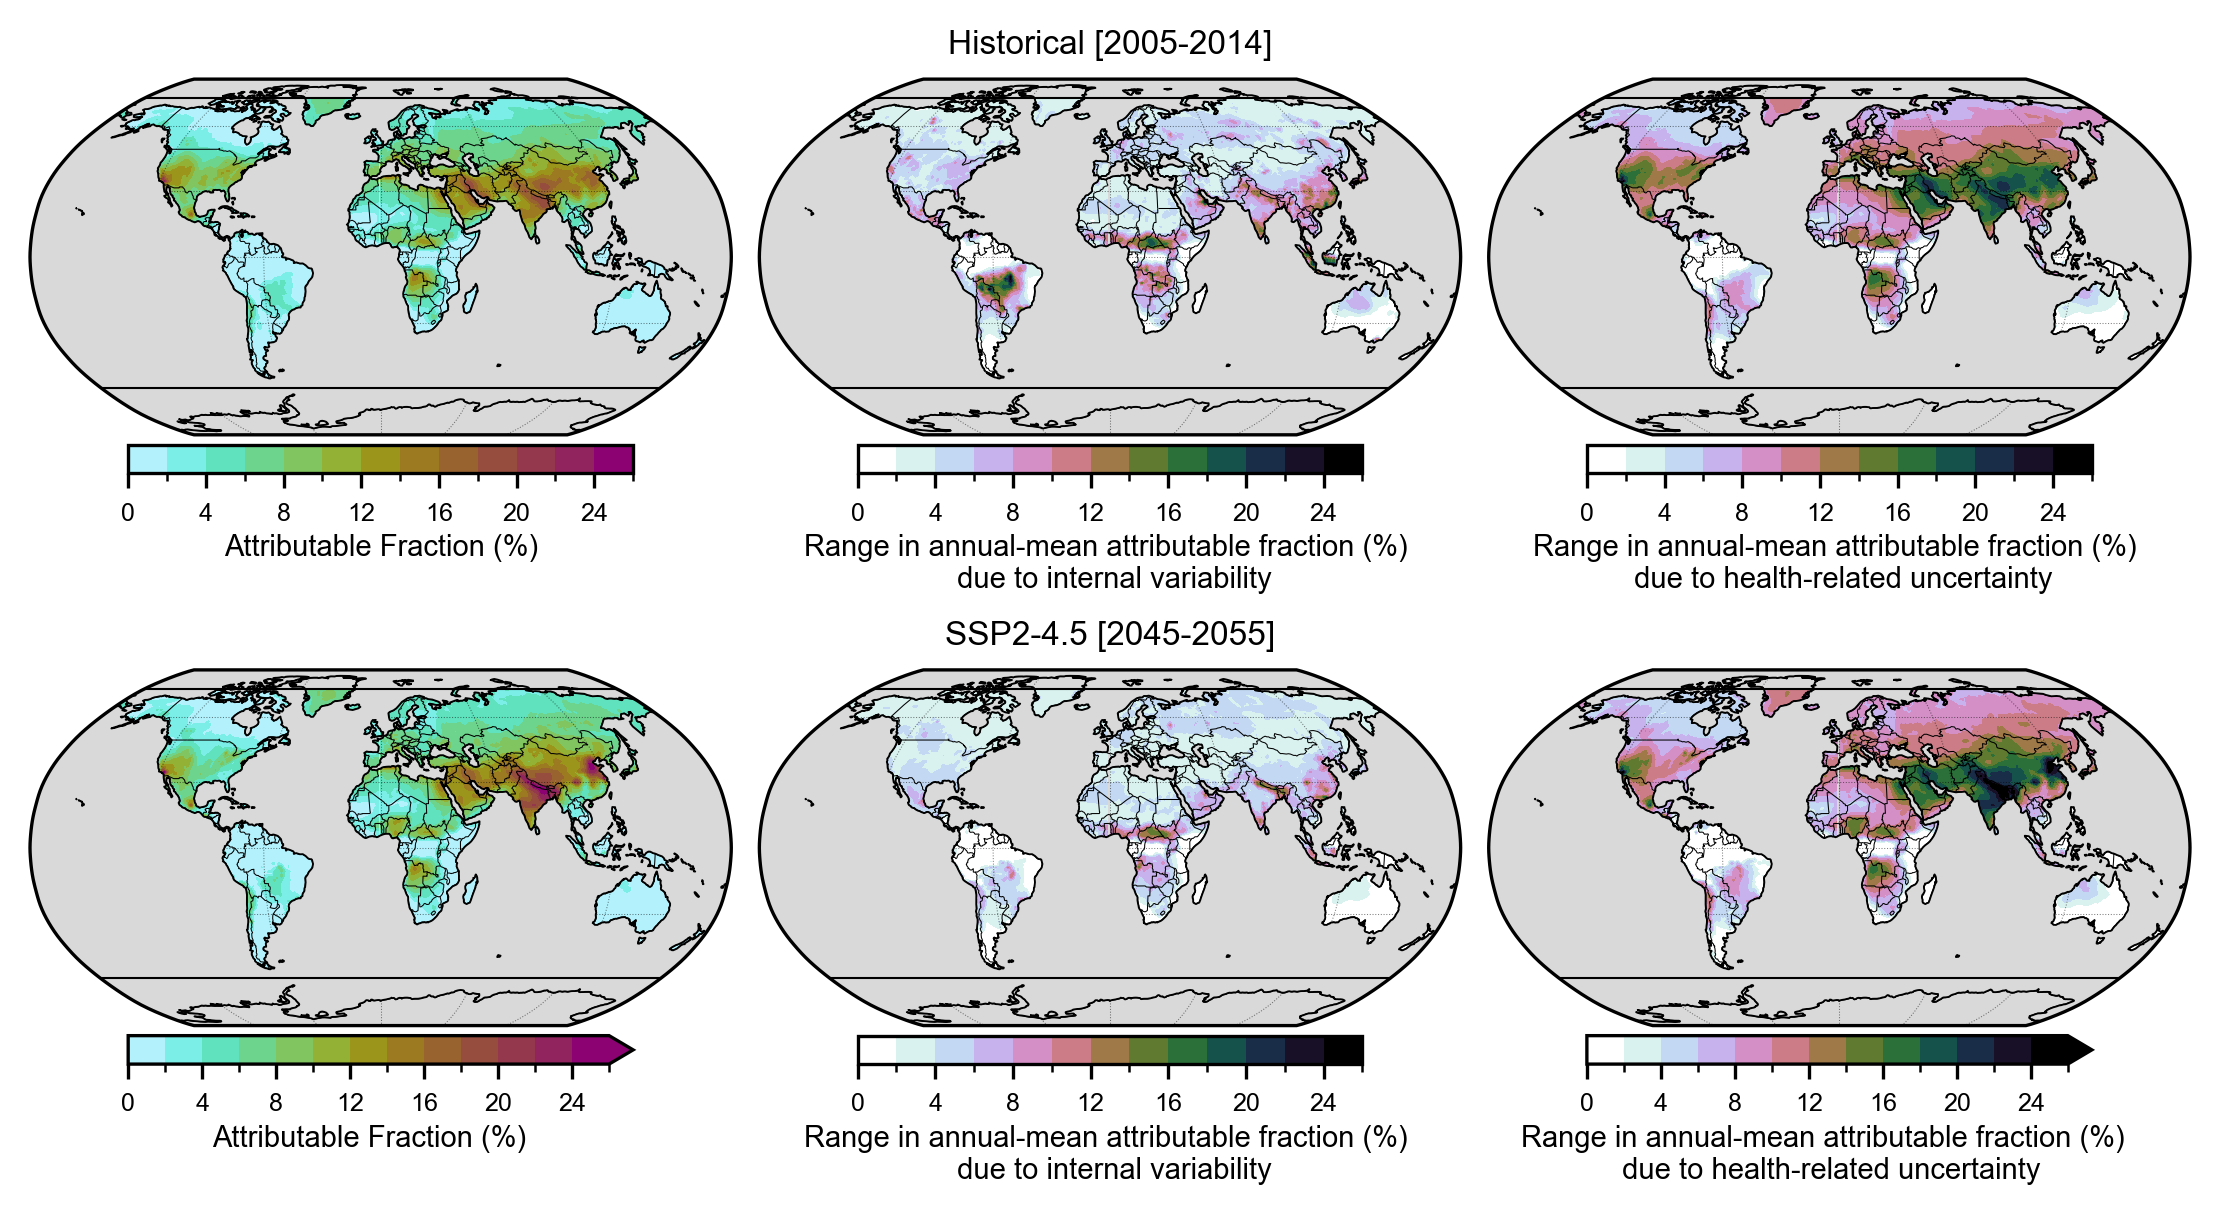

In [37]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.mpl.ticker import LatitudeFormatter, LongitudeFormatter
import matplotlib.ticker as mticker

from cmcrameri import cm 
import matplotlib as mpl
from matplotlib.gridspec import GridSpec
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes


utils.set_matplotlib_font("Arial")

lon_formatter = LongitudeFormatter(zero_direction_label=True)
lat_formatter = LatitudeFormatter()

fig_width_in = 9
fig_height_in = 4

fig = plt.figure(figsize=(fig_width_in, fig_height_in), dpi=300)

gs1 = GridSpec(
    2, 3,
    top=0.90, bottom=0.10, left=0.08, right=0.88,
    hspace=0.60, wspace=0.04
)        

proj = ccrs.Robinson(central_longitude=0)
# Column 1
ax1 = fig.add_subplot(gs1[0, 0], projection=proj)
ax2 = fig.add_subplot(gs1[1, 0], projection=proj)

# Column 2
ax3 = fig.add_subplot(gs1[0, 1], projection=proj)
ax4 = fig.add_subplot(gs1[1, 1], projection=proj)

# Column 3
ax5 = fig.add_subplot(gs1[0, 2], projection=proj)
ax6 = fig.add_subplot(gs1[1, 2], projection=proj)

axes = [ax1, ax2, ax3, ax4, ax5, ax6]

titles= [None, None, "Historical [2005-2014]", "SSP2-4.5 [2045-2055]", None , None
         ]

for ax, t in zip(axes, titles):
    ax.set_title(t, color="black", fontsize=8)
    style_map(ax)

########################################################
### Attributable Fraction ####
vmax = 26
vmin = 0
step = 2
levels = np.arange(vmin, vmax + step, step)
n_bins = len(levels) - 1

base = cm.hawaii_r
colors = base(np.linspace(0, 1, n_bins))
cmap = mpl.colors.ListedColormap(colors)
norm = mpl.colors.BoundaryNorm(levels, ncolors=n_bins, clip=False)

## --- hist AF --- ##
z_hist_central = hist_af_healthrange['osdma_bc_central_af']
m1 = z_hist_central.plot.contourf(
    ax=ax1,
    transform=ccrs.PlateCarree(),
    cmap=cmap,
    norm=norm,
    levels=levels,         
    add_colorbar=False,
    add_labels=False,
)

# cover oceans with gray
ax1.add_feature(
    cfeature.OCEAN,
    facecolor="0.85",
    edgecolor="none",
    zorder=2,
)

ax1.coastlines(linewidth=0.4, color="black", zorder=3)
add_panel_cbar(fig, ax1, m1, label="Attributable Fraction (%)")

## --- ssp AF --- ##
z_ssp_central = ssp_af_healthrange['osdma_bc_central_af']
m2 = z_ssp_central.plot.contourf(
    ax=ax2,
    transform=ccrs.PlateCarree(),
    cmap=cmap,
    norm=norm,
    levels=levels,          # or pass an explicit array of levels
    add_colorbar=False,
    add_labels=False,
)

# cover oceans with gray
ax2.add_feature(
    cfeature.OCEAN,
    facecolor="0.85",
    edgecolor="none",
    zorder=2,
)

ax2.coastlines(linewidth=0.4, color="black", zorder=3)
add_panel_cbar(fig, ax2, m2, label="Attributable Fraction (%)")

##############################################################################
## Attributable Fraction RANGE INTVAR
base = mpl.colormaps['cubehelix_r']
colors = base(np.linspace(0, 1, n_bins))
cmap = mpl.colors.ListedColormap(colors)
norm = mpl.colors.BoundaryNorm(levels, ncolors=n_bins, clip=False)


## --- hist AF range --- ##
z_hist_intvar = (
    ds_hist_af["af_bc"].max(dim=["ensemble_member", "time"])
    - ds_hist_af["af_bc"].min(dim=["ensemble_member", "time"])
)

m3 = z_hist_intvar.plot.contourf(
    ax=ax3,
    transform=ccrs.PlateCarree(),
    cmap=cmap,
    norm=norm,
    levels=levels,
    add_colorbar=False,
    add_labels=False,
)

# cover oceans with gray
ax3.add_feature(
    cfeature.OCEAN,
    facecolor="0.85",
    edgecolor="none",
    zorder=2,
)

ax3.coastlines(linewidth=0.4, color="black", zorder=3)
add_panel_cbar(fig, ax3, m3, label="Range in annual-mean attributable fraction (%) \n due to internal variability")


## --- ssp AF range --- ##
z_ssp_intvar = (
    ds_ssp_af["af_bc"].max(dim=["ensemble_member", "time"])
    - ds_ssp_af["af_bc"].min(dim=["ensemble_member", "time"])
)

m4 = z_ssp_intvar.plot.contourf(
    ax=ax4,
    transform=ccrs.PlateCarree(),
    cmap=cmap,
    norm=norm,
    levels=levels,
    add_colorbar=False,
    add_labels=False,
)

# cover oceans with gray
ax4.add_feature(
    cfeature.OCEAN,
    facecolor="0.85",
    edgecolor="none",
    zorder=2,
)

ax4.coastlines(linewidth=0.4, color="black", zorder=3)
add_panel_cbar(fig, ax4, m4, label="Range in annual-mean attributable fraction (%) \n due to internal variability")
##############################################################################

##############################################################################
## Attributable Fraction RANGE HEALTHVAR

## --- hist AF range --- ##

z_hist_health = (
    hist_af_healthrange['osdma_bc_high_af']
    - hist_af_healthrange['osdma_bc_low_af']
)

m5 = z_hist_health.plot.contourf(
    ax=ax5,
    transform=ccrs.PlateCarree(),
    cmap=cmap,
    norm=norm,
    levels=levels,
    add_colorbar=False,
    add_labels=False,
)

# cover oceans with gray
ax5.add_feature(
    cfeature.OCEAN,
    facecolor="0.85",
    edgecolor="none",
    zorder=2,
)

ax5.coastlines(linewidth=0.4, color="black", zorder=3)
add_panel_cbar(fig, ax5, m5, label="Range in annual-mean attributable fraction (%) \n due to health-related uncertainty")


## --- ssp AF range --- ##
z_ssp_health = (
    ssp_af_healthrange['osdma_bc_high_af']
    - ssp_af_healthrange['osdma_bc_low_af']
)
m6 = z_ssp_health.plot.contourf(
    ax=ax6,
    transform=ccrs.PlateCarree(),
    cmap=cmap,
    norm=norm,
    levels=levels,
    add_colorbar=False,
    add_labels=False,
)

# cover oceans with gray
ax6.add_feature(
    cfeature.OCEAN,
    facecolor="0.85",
    edgecolor="none",
    zorder=2,
)

ax6.coastlines(linewidth=0.4, color="black", zorder=3)
add_panel_cbar(fig, ax6, m6, label="Range in annual-mean attributable fraction (%) \n due to health-related uncertainty")
##############################################################################


#for axes in [ax1, ax2, ax3, ax4, ax5, ax6]:
#    plots.clip_to_obs_lat_band(axes, lat_min=-60, lat_max=75)

lons = np.linspace(-180, 180, 361)

for ax in [ax1, ax2, ax3, ax4, ax5, ax6]:
    ax.set_facecolor("0.85")
    ax.plot(
        lons, np.full_like(lons, 75),
        transform=ccrs.PlateCarree(),
        color="black",
        linewidth=0.5,
        linestyle="-",
        zorder=20,
    )
    ax.plot(
        lons, np.full_like(lons, -60),
        transform=ccrs.PlateCarree(),
        color="black",
        linewidth=0.5,
        linestyle="-",
        zorder=20,
    )

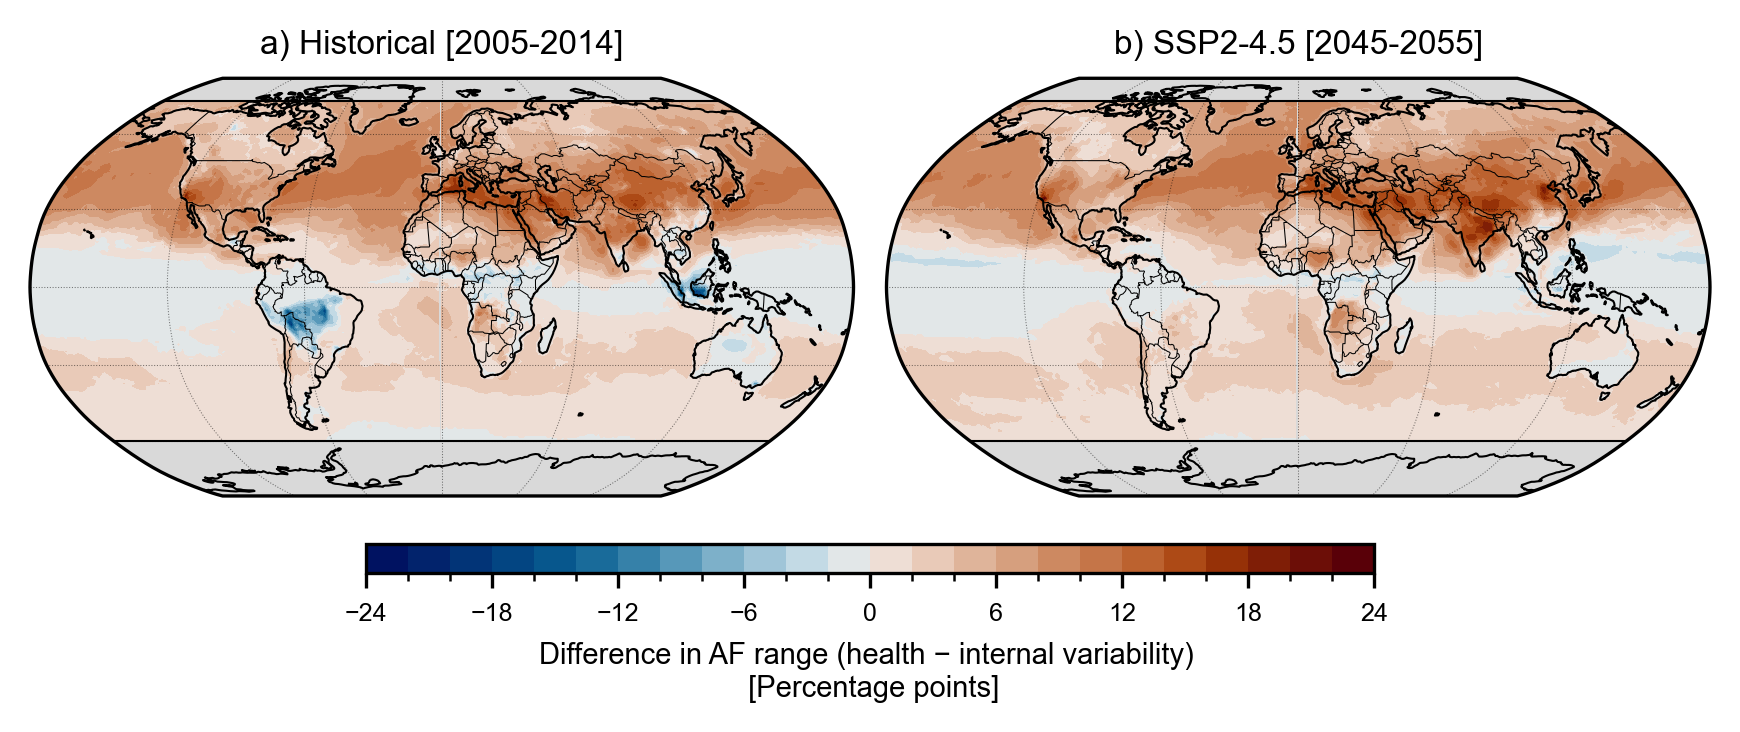

In [47]:


fig_width_in = 7
fig_height_in = 5
fig = plt.figure(figsize=(fig_width_in, fig_height_in), dpi=300)
gs1 = GridSpec(
    1, 2,
    top=0.90, bottom=0.10, left=0.08, right=0.88,
    hspace=0.5, wspace=0.04
)        
proj = ccrs.Robinson(central_longitude=0)
ax1 = fig.add_subplot(gs1[0, 0], projection=proj)
ax2 = fig.add_subplot(gs1[0, 1], projection=proj)

axes = [ax1, ax2]

titles= ["a) Historical [2005-2014]", "b) SSP2-4.5 [2045-2055]"]

for ax, title in zip(axes, titles):
    ax.set_title(title, fontsize=8)
    style_map(ax)

#a = z_hist_health-z_hist_intvar
#b = z_ssp_health-z_ssp_intvar

a = z_hist_health-z_hist_intvar

vmax = 24
vmin = -24
step = 2
levels = np.arange(vmin, vmax + step, step)
n_bins = len(levels) - 1

base = cm.vik
colors = base(np.linspace(0, 1, n_bins))
cmap = mpl.colors.ListedColormap(colors)
norm = mpl.colors.BoundaryNorm(levels, ncolors=n_bins, clip=False)

m1 = a.plot.contourf(
    ax=ax1,
    transform=ccrs.PlateCarree(),
    cmap=cmap,
    norm=norm,
    levels=levels,
    add_colorbar=False,
    add_labels=False,
)

###########

b = z_ssp_health-z_ssp_intvar

m2 = b.plot.contourf(
    ax=ax2,
    transform=ccrs.PlateCarree(),
    cmap=cmap,
    norm=norm,
    levels=levels,
    add_colorbar=False,
    add_labels=False,
)

lons = np.linspace(-180, 180, 361)

for ax in [ax1, ax2, ax3, ax4]:
    ax.set_facecolor("0.85")
    ax.plot(
        lons, np.full_like(lons, 75),
        transform=ccrs.PlateCarree(),
        color="black",
        linewidth=0.5,
        linestyle="-",
        zorder=20,
    )
    ax.plot(
        lons, np.full_like(lons, -60),
        transform=ccrs.PlateCarree(),
        color="black",
        linewidth=0.5,
        linestyle="-",
        zorder=20,
    )

cbar = fig.colorbar(
    m2,                      # or m1; both use same cmap/norm/levels
    ax=[ax1, ax2],
    orientation="horizontal",
    fraction=0.05,
    pad=0.04,
    aspect=35,
    shrink=0.6,
)
cbar.set_label("Difference in AF range (health − internal variability) \n [Percentage points]", fontsize=7)
cbar.ax.tick_params(labelsize=6)

Text(0.48, 0.4192280795590202, 'SSP2-4.5 [2045–2055]')

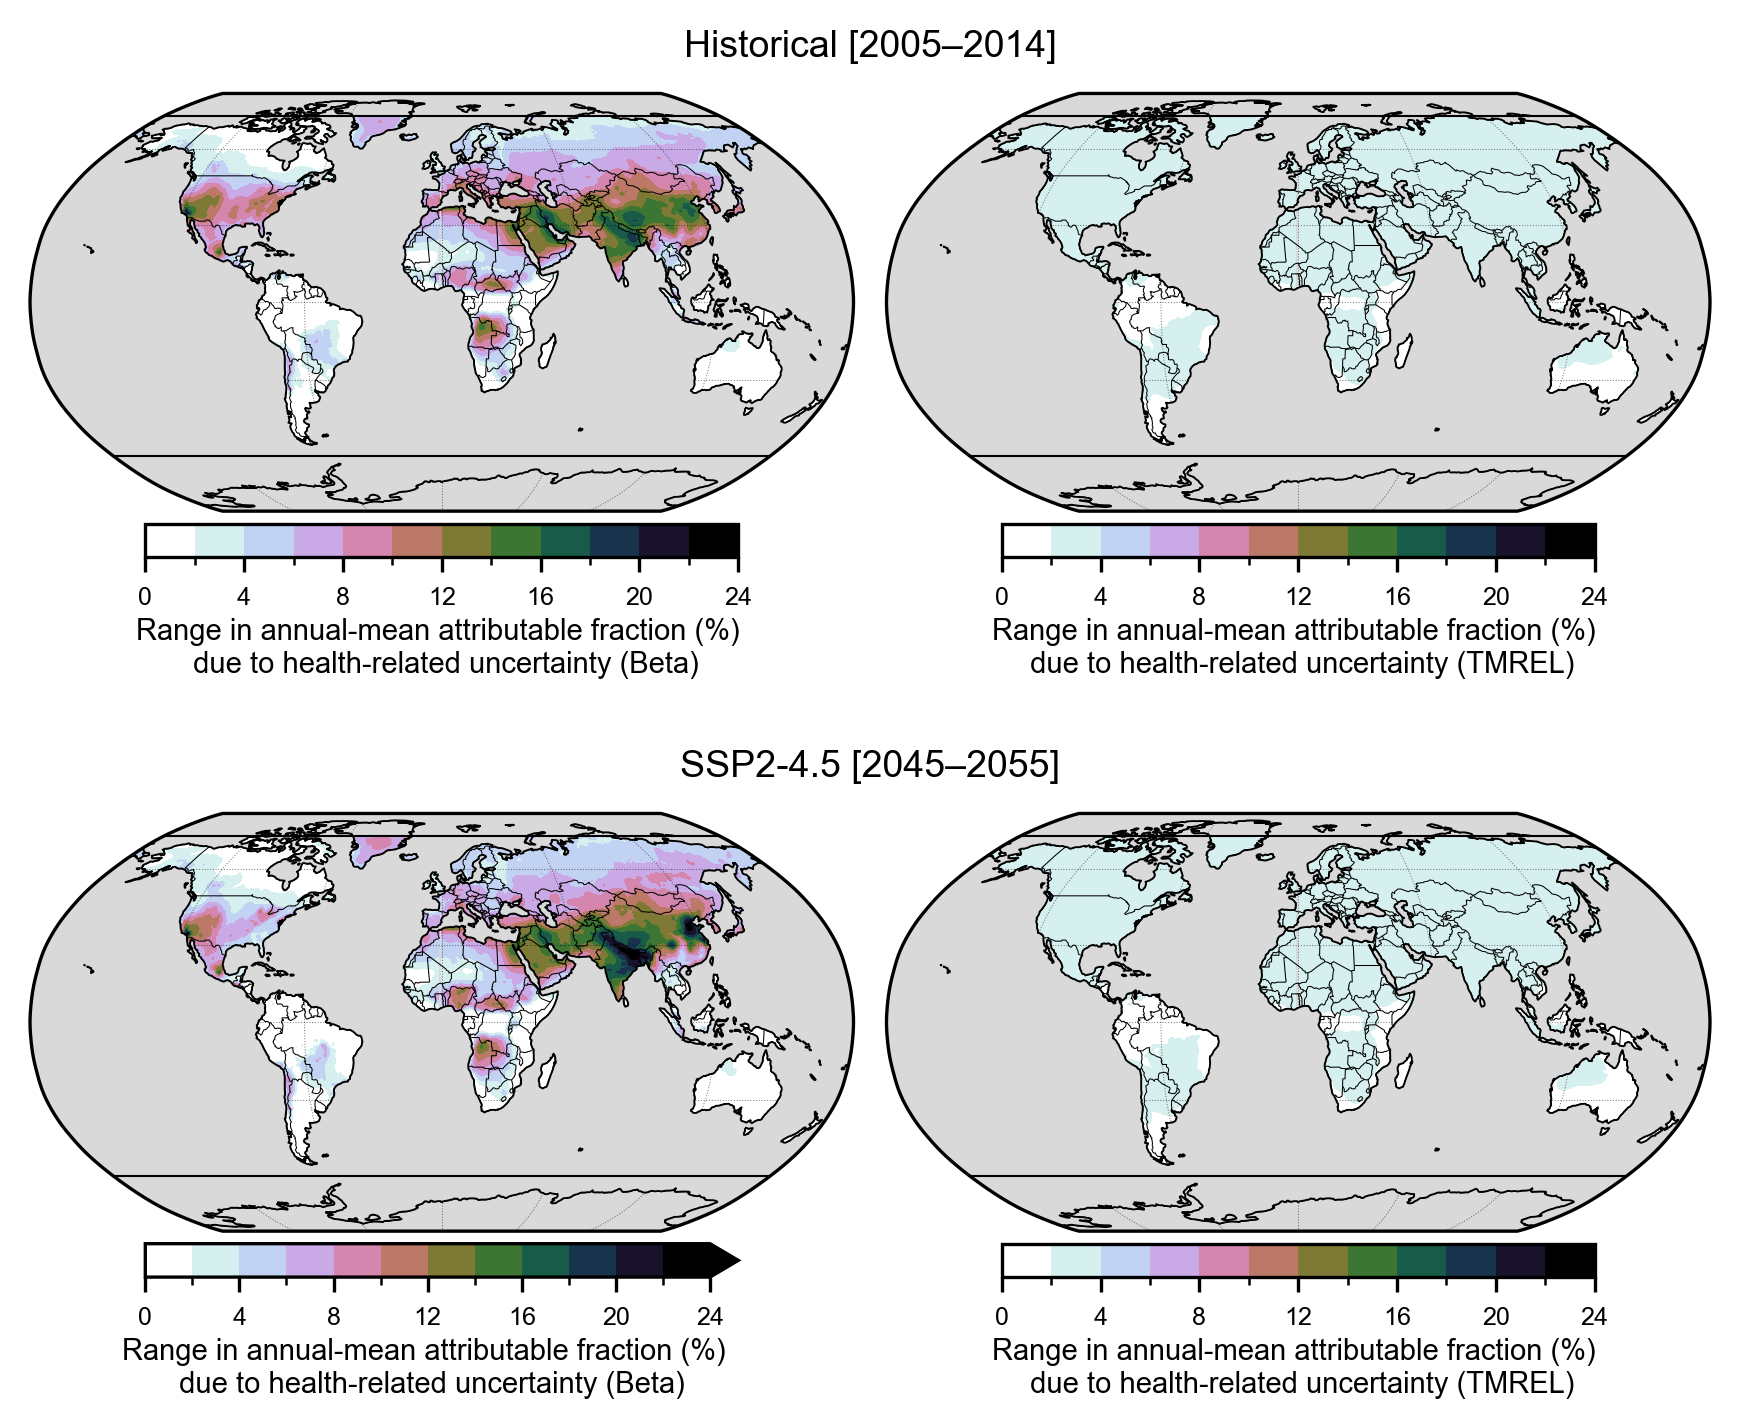

In [48]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.mpl.ticker import LatitudeFormatter, LongitudeFormatter
import matplotlib.ticker as mticker

from cmcrameri import cm 
import matplotlib as mpl
from matplotlib.gridspec import GridSpec
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes


utils.set_matplotlib_font("Arial")

lon_formatter = LongitudeFormatter(zero_direction_label=True)
lat_formatter = LatitudeFormatter()

fig_width_in = 7
fig_height_in = 5
fig = plt.figure(figsize=(fig_width_in, fig_height_in), dpi=300)
gs1 = GridSpec(
    2, 2,
    top=0.90, bottom=0.10, left=0.08, right=0.88,
    hspace=0.5, wspace=0.04
)        
proj = ccrs.Robinson(central_longitude=0)
ax1 = fig.add_subplot(gs1[0, 0], projection=proj)
ax2 = fig.add_subplot(gs1[1, 0], projection=proj)
ax3 = fig.add_subplot(gs1[0, 1], projection=proj)
ax4 = fig.add_subplot(gs1[1, 1], projection=proj)

axes = [ax1, ax2, ax3, ax4]

titles= ["Historical [2005-2014]", "SSP2-4.5 [2045-2055]", None , None
         ]

for ax in axes:
    style_map(ax)


##############################################################################
##############################################################################
## Attributable Fraction RANGE HEALTHVAR BETA
vmax = 24
vmin = 0
step = 2
levels = np.arange(vmin, vmax + step, step)
n_bins = len(levels) - 1

base = mpl.colormaps['cubehelix_r']

colors = base(np.linspace(0, 1, n_bins))
cmap = mpl.colors.ListedColormap(colors)
norm = mpl.colors.BoundaryNorm(levels, ncolors=n_bins, clip=False)

## --- hist AF range --- ##

z_range = (
    hist_af_healthrange['osdma_bc_rr_high_af']
    - hist_af_healthrange['osdma_bc_rr_low_af']
)

m1 = z_range.plot.contourf(
    ax=ax1,
    transform=ccrs.PlateCarree(),
    cmap=cmap,
    norm=norm,
    levels=levels,
    add_colorbar=False,
    add_labels=False,
)

# cover oceans with gray
ax1.add_feature(
    cfeature.OCEAN,
    facecolor="0.85",
    edgecolor="none",
    zorder=2,
)

ax1.coastlines(linewidth=0.4, color="black", zorder=3)
add_panel_cbar(fig, ax1, m1, label="Range in annual-mean attributable fraction (%) \n due to health-related uncertainty (Beta)")


## --- ssp AF range --- ##
z_range = (
    ssp_af_healthrange['osdma_bc_rr_high_af']
    - ssp_af_healthrange['osdma_bc_rr_low_af']
)
m2 = z_range.plot.contourf(
    ax=ax2,
    transform=ccrs.PlateCarree(),
    cmap=cmap,
    norm=norm,
    levels=levels,
    add_colorbar=False,
    add_labels=False,
)

# cover oceans with gray
ax2.add_feature(
    cfeature.OCEAN,
    facecolor="0.85",
    edgecolor="none",
    zorder=2,
)

ax2.coastlines(linewidth=0.4, color="black", zorder=3)
add_panel_cbar(fig, ax2, m2, label="Range in annual-mean attributable fraction (%) \n due to health-related uncertainty (Beta)")
##############################################################################

## --- hist AF range --- ##

z_range = (
    hist_af_healthrange['osdma_bc_tmrel_low_af']
    - hist_af_healthrange['osdma_bc_tmrel_high_af']
)

m3 = z_range.plot.contourf(
    ax=ax3,
    transform=ccrs.PlateCarree(),
    cmap=cmap,
    norm=norm,
    levels=levels,
    add_colorbar=False,
    add_labels=False,
)

# cover oceans with gray
ax3.add_feature(
    cfeature.OCEAN,
    facecolor="0.85",
    edgecolor="none",
    zorder=2,
)

ax3.coastlines(linewidth=0.4, color="black", zorder=3)
add_panel_cbar(fig, ax3, m3, label="Range in annual-mean attributable fraction (%) \n due to health-related uncertainty (TMREL)")


## --- ssp AF range --- ##
z_range = (
    ssp_af_healthrange['osdma_bc_tmrel_low_af']
    - ssp_af_healthrange['osdma_bc_tmrel_high_af']
)
m4 = z_range.plot.contourf(
    ax=ax4,
    transform=ccrs.PlateCarree(),
    cmap=cmap,
    norm=norm,
    levels=levels,
    add_colorbar=False,
    add_labels=False,
)

# cover oceans with gray
ax4.add_feature(
    cfeature.OCEAN,
    facecolor="0.85",
    edgecolor="none",
    zorder=2,
)

ax4.coastlines(linewidth=0.4, color="black", zorder=3)
add_panel_cbar(fig, ax4, m4, label="Range in annual-mean attributable fraction (%) \n due to health-related uncertainty (TMREL)")
##############################################################################

lons = np.linspace(-180, 180, 361)

for ax in [ax1, ax2, ax3, ax4]:
    ax.set_facecolor("0.85")
    ax.plot(
        lons, np.full_like(lons, 75),
        transform=ccrs.PlateCarree(),
        color="black",
        linewidth=0.5,
        linestyle="-",
        zorder=20,
    )
    ax.plot(
        lons, np.full_like(lons, -60),
        transform=ccrs.PlateCarree(),
        color="black",
        linewidth=0.5,
        linestyle="-",
        zorder=20,
    )

# centered row titles
top_left = ax1.get_position()
top_right = ax3.get_position()
bot_left = ax2.get_position()
bot_right = ax4.get_position()

x_top = 0.5 * (top_left.x0 + top_right.x1)
x_bot = 0.5 * (bot_left.x0 + bot_right.x1)

y_top = top_left.y1 + 0.02
y_bot = bot_left.y1 + 0.02

fig.text(
    x_top, y_top, "Historical [2005–2014]",
    ha="center", va="bottom", fontsize=9, color="black"
)

fig.text(
    x_bot, y_bot, "SSP2-4.5 [2045–2055]",
    ha="center", va="bottom", fontsize=9, color="black"
)
